Saving VK.jpg to VK.jpg
Found 28 raw detections above confidence 0.35.
Remaining detections after NMS: 22


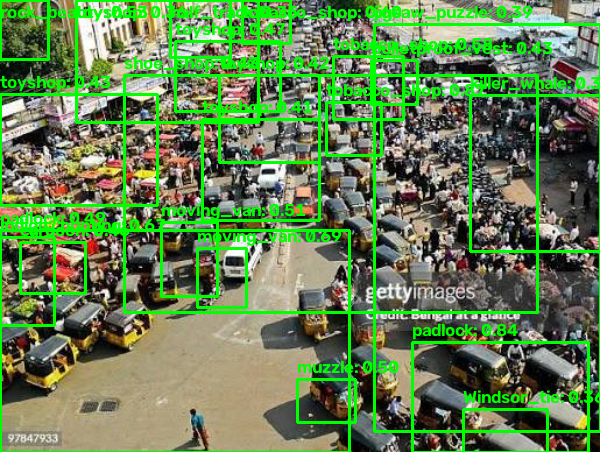

In [2]:

import os, subprocess

try:
    import cv2
    ss_ready = hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation")
except Exception:
    ss_ready = False

if not ss_ready:
    subprocess.run(
        "pip uninstall -y -q opencv-python opencv-python-headless "
        "opencv-contrib-python opencv-contrib-python-headless",
        shell=True
    )
    subprocess.run("pip install -q opencv-contrib-python", shell=True)
    os.kill(os.getpid(), 9)

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

model = VGG16(weights='imagenet', include_top=True)

def get_region_proposals(img, max_regions=200):
    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()

        boxes = [(x, y, w, h) for (x, y, w, h) in ss.process()
                 if w > 40 and h > 40]

        if boxes:
            return boxes[:max_regions]
    except Exception:
        pass

    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W*s), int(H*s)

        for y in range(0, H-bh+1, max(1, bh//2)):
            for x in range(0, W-bw+1, max(1, bw//2)):
                boxes.append((x, y, bw, bh))

    return boxes[:max_regions]

def non_max_suppression(dets, iou_thr=0.3):
    if not dets:
        return []

    boxes = np.array([[x, y, x+w, y+h]
                      for (x, y, w, h), _, _ in dets], dtype=float)

    scores = np.array([s for _, _, s in dets])
    order = scores.argsort()[::-1]
    keep = []

    while len(order):
        i = order[0]
        keep.append(i)
        rest = order[1:]

        xx1 = np.maximum(boxes[i,0], boxes[rest,0])
        yy1 = np.maximum(boxes[i,1], boxes[rest,1])
        xx2 = np.minimum(boxes[i,2], boxes[rest,2])
        yy2 = np.minimum(boxes[i,3], boxes[rest,3])

        w = np.clip(xx2-xx1, 0, None)
        h = np.clip(yy2-yy1, 0, None)
        inter = w*h

        area_i = (boxes[i,2]-boxes[i,0])*(boxes[i,3]-boxes[i,1])
        area_r = (boxes[rest,2]-boxes[rest,0])*(boxes[rest,3]-boxes[rest,1])

        order = rest[inter/(area_i+area_r-inter+1e-9) < iou_thr]

    return [dets[i] for i in keep]

# Ensure VGG16 model is instantiated
if 'model' not in globals():
    print("Initializing VGG16 model...")
    model = VGG16(weights='imagenet', include_top=True)

uploaded = files.upload()
image_path = next(iter(uploaded))

img = cv2.imread(image_path)
H0, W0 = img.shape[:2]

img = cv2.resize(img, (600, int(H0 * 600.0 / W0)))

boxes = get_region_proposals(img, max_regions=200)

crops = np.array([
    cv2.resize(img[y:y+h, x:x+w], (224, 224))
    for (x, y, w, h) in boxes
], dtype=np.float32)

preds = model.predict(
    preprocess_input(crops),
    batch_size=32,
    verbose=0
)

detections = []

# Let's decode the VGG16 predictions with a lower, more realistic threshold (e.g., 0.35)
threshold = 0.35

for (x, y, w, h), p in zip(boxes, preds):
    _, label, prob = decode_predictions(p[None], top=1)[0][0]

    if prob > threshold:
        detections.append(((x, y, w, h), label, float(prob)))

print(f"Found {len(detections)} raw detections above confidence {threshold}.")

# Run non-maximum suppression to clean up overlaps
detections = non_max_suppression(detections, iou_thr=0.3)
print(f"Remaining detections after NMS: {len(detections)}")

# Copy original image to avoid drawing over old lines if re-run
annotated_img = img.copy()

for (x, y, w, h), label, score in detections:
    cv2.rectangle(annotated_img, (x, y), (x+w, y+h), (0, 255, 0), 2)

    cv2.putText(annotated_img, f"{label}: {score:.2f}",
                (x, max(18, y-6)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                (0, 255, 0), 2)

cv2_imshow(annotated_img)